# Animations

`scene.animate(update, frames)` draws the scene, then calls `update(i)` before each further
frame `i`. The update function changes the geometry — here it turns a box a little. All frames
are captured first, so the animation plays smoothly and can loop.

* **plotly** gives a figure with a play button and a slider. It runs in the browser, also in an
  exported HTML file, and the view can be rotated while it plays.
* **matplotlib** plays live with ipympl (`%matplotlib widget`); with the default inline backend,
  Jupyter shows it as an HTML player.

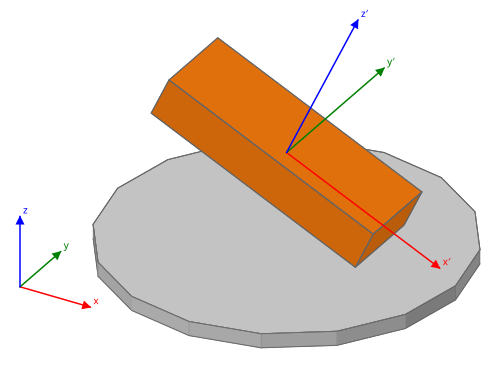

In [1]:
from minigeo import Scene
from minigeo.geometry import BaseBox, BaseCylinder


def turning_box_scene():
    """A box standing on a disc, tilted, turning around its own long axis x'."""
    scene = Scene()
    base = scene.add(BaseCylinder([0, 0, 0], dimensions=[1.2, 0.1]), fill="lightgray")
    box = BaseBox(base.anchor("top"), dimensions=[1.6, 0.6, 0.3], anchor="bottom")
    box.place("center", at=base.anchor("top") + [0, 0, 0.6])
    box.rotate("y", 25, about="center")
    scene.add(box, fill="C1", frame=True)
    scene.add_frame([-1.2, -1.2, 0], length=0.5)
    return scene, box


scene, box = turning_box_scene()
scene

## With plotly

Each frame turns the box by 10° around its own x' axis; 36 frames make a full turn.
Press ▶ to play. `figure.write_html("turning_box.html")` saves it as a web page.

In [ ]:
scene, box = turning_box_scene()
scene.animate(lambda frame: box.rotate("x'", 10, about="center"), frames=36, height=450)

## With matplotlib

With the default inline backend the animation becomes an HTML player: press ▶ to play. All frames
are drawn first, which takes a moment. `animation.save("turning_box.gif")` writes a GIF.

In [ ]:
scene, box = turning_box_scene()
scene.animate(lambda frame: box.rotate("x'", 10, about="center"), frames=36, backend="matplotlib", interval=60)

### Live with ipympl

With `%matplotlib widget` (needs `pip install ipympl`) the animation plays in the live figure, and
the view can be rotated with the mouse while it runs. Keep a reference to the animation (here
`animation`), otherwise Python may stop it.

In [ ]:
%matplotlib widget
scene, box = turning_box_scene()
animation = scene.animate(lambda frame: box.rotate("x'", 10, about="center"), frames=36, backend="matplotlib", interval=60)